In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

In [ ]:
import glob
import os
import kagglehub
import pandas as pd

# 1. Baixa a versão mais recente do dataset do Kaggle
path = kagglehub.dataset_download("alanvourch/tmdb-movies-daily-updates")

# 2. Localiza automaticamente o arquivo .csv dentro da pasta baixada
csv_path = glob.glob(os.path.join(path, "*.csv"))[0]
print("Carregando:", csv_path)

# 3. Lê o CSV (low_memory=False evita avisos de tipos mistos em colunas grandes)
df = pd.read_csv(csv_path, low_memory=False)
print(f"Shape: {df.shape}")
df.head()

100%|██████████| 330M/330M [00:05<00:00, 65.2MB/s]

Extracting files...


Carregando: /root/.cache/kagglehub/datasets/alanvourch/tmdb-movies-daily-updates/versions/1065/TMDB_all_movies.csv
Shape: (1276502, 30)


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,...,director,director_of_photography,writers,producers,music_composer,imdb_rating,imdb_votes,poster_path,keywords,certification_us
0,2,Ariel,7.100,382.0,Released,1988-10-21,0.0,73.0,0.0,tt0094675,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Aki Kaurismäki,NaN,7.4,10098.0,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,"prison|underdog|helsinki, finland|factory work...",NaN
1,3,Shadows in Paradise,7.300,457.0,Released,1986-10-17,0.0,74.0,0.0,tt0092149,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Mika Kaurismäki,NaN,7.4,8925.0,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,"helsinki, finland|salesclerk|garbage",NR
2,5,Four Rooms,5.900,2933.0,Released,1995-12-09,4257354.0,98.0,4000000.0,tt0113101,...,"Robert Rodriguez, Alexandre Rockwell, Allison ...","Andrzej Sekula, Guillermo Navarro, Rodrigo Gar...","Quentin Tarantino, Allison Anders, Alexandre R...","Quentin Tarantino, Alexandre Rockwell, Lawrenc...",Combustible Edison,6.7,118078.0,/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,hotel|new year's eve|witch|bet|sperm|hotel roo...,R
3,6,Judgment Night,6.455,397.0,Released,1993-10-15,12136938.0,110.0,21000000.0,tt0107286,...,Stephen Hopkins,Peter Levy,"Lewis Colick, Jere Cunningham","Gene Levy, Lloyd Segan, Marilyn Vance",Alan Silvestri,6.6,21497.0,/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,"drug dealer|chicago, illinois|escape|one night...",R
4,8,Life in Loops (A Megacities RMX),7.300,34.0,Released,2006-01-01,0.0,80.0,42000.0,tt0825671,...,Timo Novotny,Wolfgang Thaler,"Michael Glawogger, Timo Novotny","Timo Novotny, Ulrich Gehmacher",NaN,8.1,285.0,/7ln81BRnPR2wqxuITZxEciCe1lc.jpg,megacities,NaN


In [ ]:
df.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,...,director,director_of_photography,writers,producers,music_composer,imdb_rating,imdb_votes,poster_path,keywords,certification_us
0,2,Ariel,7.100,382.0,Released,1988-10-21,0.0,73.0,0.0,tt0094675,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Aki Kaurismäki,NaN,7.4,10098.0,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,"prison|underdog|helsinki, finland|factory work...",NaN
1,3,Shadows in Paradise,7.300,457.0,Released,1986-10-17,0.0,74.0,0.0,tt0092149,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Mika Kaurismäki,NaN,7.4,8925.0,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,"helsinki, finland|salesclerk|garbage",NR
2,5,Four Rooms,5.900,2933.0,Released,1995-12-09,4257354.0,98.0,4000000.0,tt0113101,...,"Robert Rodriguez, Alexandre Rockwell, Allison ...","Andrzej Sekula, Guillermo Navarro, Rodrigo Gar...","Quentin Tarantino, Allison Anders, Alexandre R...","Quentin Tarantino, Alexandre Rockwell, Lawrenc...",Combustible Edison,6.7,118078.0,/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,hotel|new year's eve|witch|bet|sperm|hotel roo...,R
3,6,Judgment Night,6.455,397.0,Released,1993-10-15,12136938.0,110.0,21000000.0,tt0107286,...,Stephen Hopkins,Peter Levy,"Lewis Colick, Jere Cunningham","Gene Levy, Lloyd Segan, Marilyn Vance",Alan Silvestri,6.6,21497.0,/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,"drug dealer|chicago, illinois|escape|one night...",R
4,8,Life in Loops (A Megacities RMX),7.300,34.0,Released,2006-01-01,0.0,80.0,42000.0,tt0825671,...,Timo Novotny,Wolfgang Thaler,"Michael Glawogger, Timo Novotny","Timo Novotny, Ulrich Gehmacher",NaN,8.1,285.0,/7ln81BRnPR2wqxuITZxEciCe1lc.jpg,megacities,NaN


In [ ]:
df.shape

(1276502, 30)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1276502 entries, 0 to 1276501
Data columns (total 30 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   id                       1276502 non-null  int64  
 1   title                    1276488 non-null  object 
 2   vote_average             1276502 non-null  float64
 3   vote_count               1276502 non-null  float64
 4   status                   1276502 non-null  object 
 5   release_date             1138122 non-null  object 
 6   revenue                  1276502 non-null  float64
 7   runtime                  1276502 non-null  float64
 8   budget                   1276502 non-null  float64
 9   imdb_id                  700749 non-null   object 
 10  original_language        1276502 non-null  object 
 11  original_title           1276488 non-null  object 
 12  overview                 1078745 non-null  object 
 13  popularity               1276502 non-null 

In [ ]:
df.describe()

,id,vote_average,vote_count,revenue,runtime,budget,popularity,imdb_rating,imdb_votes
count,1.276502e+06,1.276502e+06,1.276502e+06,1.276502e+06,1.276502e+06,1.276502e+06,1.276502e+06,484496.000000,4.844960e+05
mean,9.177384e+05,2.056886e+00,2.240552e+01,6.699253e+05,4.323275e+01,2.699201e+05,7.541799e-01,6.246892,2.794523e+03
std,5.197428e+05,3.138499e+00,3.702203e+02,1.669885e+07,5.389944e+01,4.794604e+06,1.798246e+00,1.325823,3.272457e+04
min,2.000000e+00,0.000000e+00,0.000000e+00,-1.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,5.000000e+00
25%,4.695960e+05,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,9.840000e-02,5.500000,2.000000e+01
50%,9.049575e+05,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+01,0.000000e+00,6.000000e-01,6.400000,5.800000e+01
75%,1.372956e+06,5.000000e+00,1.000000e+00,0.000000e+00,8.400000e+01,0.000000e+00,9.150000e-01,7.100000,2.590000e+02
max,1.827154e+06,1.000000e+01,4.190800e+04,2.942650e+09,1.440000e+04,1.000000e+09,5.986444e+02,10.000000,3.264913e+06


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum()

,0
id,0
title,14
vote_average,0
vote_count,0
status,0
release_date,138380
revenue,0
runtime,0
budget,0
imdb_id,575753


In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['title', 'release_date', 'imdb_id', 'original_title', 'overview', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'cast', 'director', 'director_of_photography', 'writers', 'producers', 'music_composer', 'imdb_rating', 'imdb_votes', 'poster_path', 'keywords', 'certification_us']
title                           14
release_date                138380
imdb_id                     575753
original_title                  14
overview                    197757
tagline                    1079517
genres                      336852
production_companies        655401
production_countries        470643
spoken_languages            462704
cast                        400383
director                    203001
director_of_photography     920207
writers                     623402
producers                   828998
music_composer             1124643
imdb_rating                 792006
imdb_votes                  792006
poster_path                

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

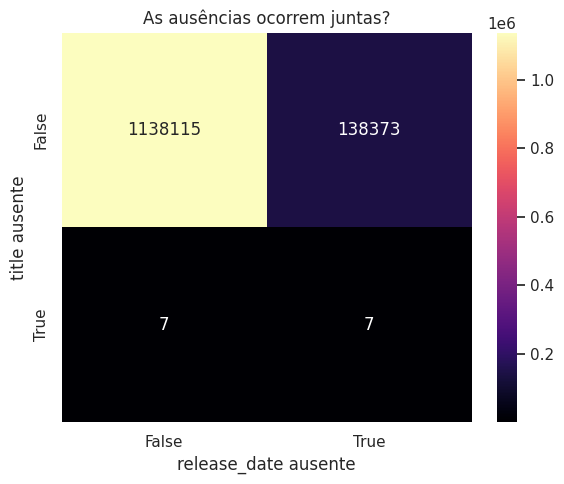

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()